In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder

In [40]:
df = pd.read_csv(r"E:\e commerce return\ecommerce_return_prediction (1).csv")

In [41]:
df.head()

,customer_age,customer_tenure_months,past_purchase_count,past_return_rate,product_price,product_rating,product_category,size_issue,product_condition,discount_percent,...,shipping_method,expected_delivery_days,actual_delivery_days,delivery_delay_days,session_length_minutes,num_product_views,num_previous_visits,cart_additions,wishlist_additions,returned
0,56,2,21,0.124,17.00,3.0,Clothing,0,good,0,...,Next Day,3,3,0,25.2,8,6,3,3,0
1,69,7,13,0.160,8.00,4.0,Footwear,1,good,20,...,Standard,2,3,1,17.2,4,2,4,0,0
2,46,2,17,0.097,68.20,4.0,Footwear,0,good,25,...,Standard,4,4,0,26.6,12,3,5,2,0
3,32,32,21,0.128,26.38,4.0,Footwear,0,good,10,...,Express,2,2,0,6.3,8,5,3,0,1
4,60,12,13,0.240,33.27,5.0,Home & Kitchen,0,good,0,...,Standard,5,5,0,42.9,5,6,4,3,0


In [42]:
df.shape
df.info()
df.isnull().sum()
df.duplicated().sum()

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   customer_age            30000 non-null  int64  
 1   customer_tenure_months  30000 non-null  int64  
 2   past_purchase_count     30000 non-null  int64  
 3   past_return_rate        30000 non-null  float64
 4   product_price           30000 non-null  float64
 5   product_rating          30000 non-null  float64
 6   product_category        30000 non-null  str    
 7   size_issue              30000 non-null  int64  
 8   product_condition       30000 non-null  str    
 9   discount_percent        30000 non-null  int64  
 10  used_coupon             30000 non-null  int64  
 11  quantity                30000 non-null  int64  
 12  payment_method          30000 non-null  str    
 13  shipping_method         30000 non-null  str    
 14  expected_delivery_days  30000 non-null  int64  
 

np.int64(0)

In [43]:
print(df["returned"].value_counts())
print(df["returned"].value_counts(normalize=True) * 100)

returned
0    16049
1    13951
Name: count, dtype: int64
returned
0    53.496667
1    46.503333
Name: proportion, dtype: float64


In [44]:
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

numerical_cols.remove("returned")

categorical_cols = df.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['customer_age', 'customer_tenure_months', 'past_purchase_count', 'past_return_rate', 'product_price', 'product_rating', 'size_issue', 'discount_percent', 'used_coupon', 'quantity', 'expected_delivery_days', 'actual_delivery_days', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'num_previous_visits', 'cart_additions', 'wishlist_additions']
Categorical columns: ['product_category', 'product_condition', 'payment_method', 'shipping_method']


In [45]:
df[numerical_cols].describe()

,customer_age,customer_tenure_months,past_purchase_count,past_return_rate,product_price,product_rating,size_issue,discount_percent,used_coupon,quantity,expected_delivery_days,actual_delivery_days,delivery_delay_days,session_length_minutes,num_product_views,num_previous_visits,cart_additions,wishlist_additions
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.0,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.00000,30000.000000,30000.000000
mean,43.952533,18.096767,11.681100,0.221337,53.583457,3.623300,0.160833,17.258500,0.0,1.360167,3.897367,4.689133,0.791767,11.939373,6.989600,3.52220,2.584567,1.204800
std,15.269931,17.961990,6.219203,0.130978,46.833094,1.168407,0.367383,14.637582,0.0,0.687310,1.378609,1.889395,1.275850,6.905553,2.620748,1.87548,1.475643,1.091862
min,18.000000,1.000000,1.000000,0.001000,8.000000,1.000000,0.000000,0.000000,0.0,1.000000,2.000000,2.000000,0.000000,1.000000,1.000000,0.00000,1.000000,0.000000
25%,31.000000,5.000000,7.000000,0.120000,24.220000,3.000000,0.000000,0.000000,0.0,1.000000,3.000000,3.000000,0.000000,6.800000,5.000000,2.00000,1.000000,0.000000
50%,44.000000,13.000000,11.000000,0.201000,40.150000,4.000000,0.000000,15.000000,0.0,1.000000,4.000000,4.000000,0.000000,10.700000,7.000000,3.00000,2.000000,1.000000
75%,57.000000,25.000000,15.000000,0.301000,66.920000,4.000000,0.000000,25.000000,0.0,2.000000,5.000000,6.000000,1.000000,15.600000,9.000000,5.00000,3.000000,2.000000
max,70.000000,120.000000,56.000000,0.862000,650.000000,5.000000,1.000000,60.000000,0.0,4.000000,7.000000,13.000000,6.000000,61.700000,20.000000,13.00000,11.000000,8.000000


In [46]:
for col in categorical_cols:
    print("\n", col)
    print(df[col].value_counts())


 product_category
product_category
Clothing          9544
Electronics       5450
Footwear          5288
Home & Kitchen    4310
Beauty            3030
Sports            2378
Name: count, dtype: int64

 product_condition
product_condition
good           24551
minor_issue     3883
damaged         1566
Name: count, dtype: int64

 payment_method
payment_method
Credit Card       13486
Debit Card         7509
Digital Wallet     5958
COD                3047
Name: count, dtype: int64

 shipping_method
shipping_method
Standard    16502
Express     10536
Next Day     2962
Name: count, dtype: int64


In [47]:
df["delivery_delay_days"] = df["delivery_delay_days"].clip(lower=0)

print(df["delivery_delay_days"].min())

0


In [48]:
X = df.drop(columns=["returned"])
y = df["returned"]

In [49]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42,
    stratify=y_train_val
)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (18000, 22)
X_val: (6000, 22)
X_test: (6000, 22)


In [50]:
numerical_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['customer_age', 'customer_tenure_months', 'past_purchase_count', 'past_return_rate', 'product_price', 'product_rating', 'size_issue', 'discount_percent', 'used_coupon', 'quantity', 'expected_delivery_days', 'actual_delivery_days', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'num_previous_visits', 'cart_additions', 'wishlist_additions']
Categorical columns: ['product_category', 'product_condition', 'payment_method', 'shipping_method']


In [51]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_val_cat = encoder.transform(X_val[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

print("X_train_cat:", X_train_cat.shape)
print("X_val_cat:", X_val_cat.shape)
print("X_test_cat:", X_test_cat.shape)

X_train_cat: (18000, 16)
X_val_cat: (6000, 16)
X_test_cat: (6000, 16)


In [52]:
from sklearn.preprocessing import OneHotEncoder

encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_val_cat = encoder.transform(X_val[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

print("X_train_cat:", X_train_cat.shape)
print("X_val_cat:", X_val_cat.shape)
print("X_test_cat:", X_test_cat.shape)

X_train_cat: (18000, 16)
X_val_cat: (6000, 16)
X_test_cat: (6000, 16)


In [53]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train[numerical_cols])
X_val_num_scaled = scaler.transform(X_val[numerical_cols])
X_test_num_scaled = scaler.transform(X_test[numerical_cols])

print("X_train_num_scaled:", X_train_num_scaled.shape)
print("X_val_num_scaled:", X_val_num_scaled.shape)
print("X_test_num_scaled:", X_test_num_scaled.shape)

X_train_num_scaled: (18000, 18)
X_val_num_scaled: (6000, 18)
X_test_num_scaled: (6000, 18)


In [54]:
X_train_scaled = np.hstack([X_train_num_scaled, X_train_cat])
X_val_scaled = np.hstack([X_val_num_scaled, X_val_cat])
X_test_scaled = np.hstack([X_test_num_scaled, X_test_cat])

print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (18000, 34)
X_val_scaled: (6000, 34)
X_test_scaled: (6000, 34)


In [55]:
print("X_train_scaled:", X_train_scaled.shape)
print("X_val_scaled:", X_val_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (18000, 34)
X_val_scaled: (6000, 34)
X_test_scaled: (6000, 34)


In [56]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def compute_cost(y, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    cost = -np.mean(
        y * np.log(y_pred) +
        (1 - y) * np.log(1 - y_pred)
    )

    return cost

In [57]:
def logistic_regression(X, y, learning_rate, iterations):

    m, n = X.shape

    weights = np.zeros(n)
    bias = 0

    cost_history = []

    for i in range(iterations):

        z = np.dot(X, weights) + bias
        y_pred = sigmoid(z)

        cost = compute_cost(y, y_pred)
        cost_history.append(cost)

        dw = np.dot(X.T, y_pred - y) / m
        db = np.sum(y_pred - y) / m

        weights -= learning_rate * dw
        bias -= learning_rate * db

    return weights, bias, cost_history

In [58]:
learning_rates = [0.001, 0.01, 0.1, 1.0]

results = {}

for lr in learning_rates:

    weights_lr, bias_lr, cost_history_lr = logistic_regression(
        X_train_scaled,
        y_train.values,
        learning_rate=lr,
        iterations=1000
    )

    results[lr] = cost_history_lr

    print(f"Learning Rate: {lr}")
    print(f"Initial Cost: {cost_history_lr[0]:.6f}")
    print(f"Final Cost: {cost_history_lr[-1]:.6f}")
    print()

Learning Rate: 0.001
Initial Cost: 0.693147
Final Cost: 0.622484

Learning Rate: 0.01
Initial Cost: 0.693147
Final Cost: 0.489038

Learning Rate: 0.1
Initial Cost: 0.693147
Final Cost: 0.451579

Learning Rate: 1.0
Initial Cost: 0.693147
Final Cost: 0.449096



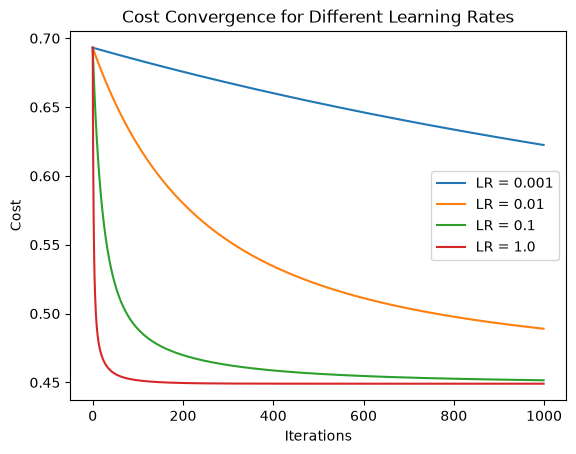

In [59]:
for lr in learning_rates:
    plt.plot(results[lr], label=f"LR = {lr}")

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Cost Convergence for Different Learning Rates")
plt.legend()
plt.show()

In [60]:
best_lr = 1.0

weights, bias, cost_history = logistic_regression(
    X_train_scaled,
    y_train.values,
    learning_rate=best_lr,
    iterations=1000
)

print("Best Learning Rate:", best_lr)
print("Initial Cost:", cost_history[0])
print("Final Cost:", cost_history[-1])

Best Learning Rate: 1.0
Initial Cost: 0.6931471805599453
Final Cost: 0.44909557350680224


In [61]:
train_prob = sigmoid(np.dot(X_train_scaled, weights) + bias)
val_prob = sigmoid(np.dot(X_val_scaled, weights) + bias)
test_prob = sigmoid(np.dot(X_test_scaled, weights) + bias)

train_pred = (train_prob >= 0.5).astype(int)
val_pred = (val_prob >= 0.5).astype(int)
test_pred = (test_prob >= 0.5).astype(int)

In [62]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Validation Accuracy:", accuracy_score(y_val, val_pred))
print("Test Accuracy:", accuracy_score(y_test, test_pred))

print("\nTest Precision:", precision_score(y_test, test_pred))
print("Test Recall:", recall_score(y_test, test_pred))
print("Test F1-score:", f1_score(y_test, test_pred))

Training Accuracy: 0.7838333333333334
Validation Accuracy: 0.782
Test Accuracy: 0.7795

Test Precision: 0.7713651498335183
Test Recall: 0.7473118279569892
Test F1-score: 0.7591480065537958


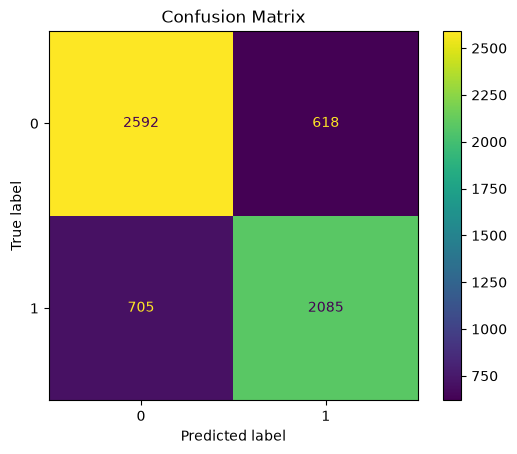

In [63]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Confusion Matrix")
plt.show()

In [64]:
from sklearn.metrics import classification_report

print(classification_report(y_test, test_pred))

              precision    recall  f1-score   support

           0       0.79      0.81      0.80      3210
           1       0.77      0.75      0.76      2790

    accuracy                           0.78      6000
   macro avg       0.78      0.78      0.78      6000
weighted avg       0.78      0.78      0.78      6000



AUC: 0.8625057224846191


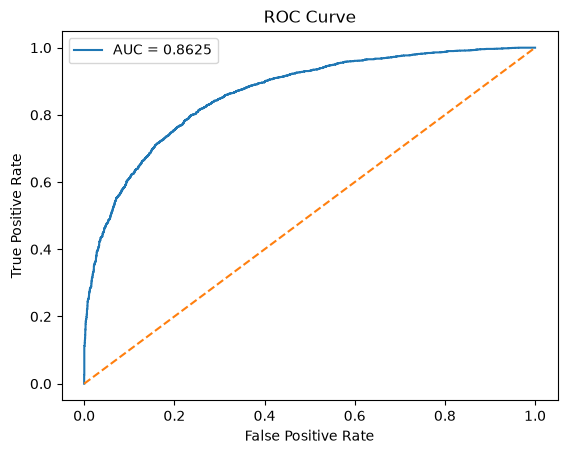

In [65]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(y_test, test_prob)

auc_score = roc_auc_score(y_test, test_prob)

print("AUC:", auc_score)

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [66]:
print("Number of X columns:", len(X.columns))
print("Number of weights:", len(weights))
print("X shape:", X.shape)
print("Weights shape:", weights.shape)

Number of X columns: 22
Number of weights: 34
X shape: (30000, 22)
Weights shape: (34,)


In [67]:
print(X.columns.tolist())

['customer_age', 'customer_tenure_months', 'past_purchase_count', 'past_return_rate', 'product_price', 'product_rating', 'product_category', 'size_issue', 'product_condition', 'discount_percent', 'used_coupon', 'quantity', 'payment_method', 'shipping_method', 'expected_delivery_days', 'actual_delivery_days', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'num_previous_visits', 'cart_additions', 'wishlist_additions']


In [68]:
print("Variables containing 'one':")
print([x for x in list(globals().keys()) if "one" in x.lower()])

print("\nVariables containing 'enc':")
print([x for x in list(globals().keys()) if "enc" in x.lower()])

Variables containing 'one':
['OneHotEncoder']

Variables containing 'enc':
['OneHotEncoder', 'encoder']


In [69]:
feature_names = encoder.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("Number of weights:", len(weights))

Number of feature names: 16
Number of weights: 34


In [70]:
print("Weights:", len(weights))

print("\nEncoder input columns:")
print(encoder.feature_names_in_)

print("\nEncoder output columns:")
print(len(encoder.get_feature_names_out()))
print(encoder.get_feature_names_out())


Weights: 34

Encoder input columns:
['product_category' 'product_condition' 'payment_method' 'shipping_method']

Encoder output columns:
16
['product_category_Beauty' 'product_category_Clothing'
 'product_category_Electronics' 'product_category_Footwear'
 'product_category_Home & Kitchen' 'product_category_Sports'
 'product_condition_damaged' 'product_condition_good'
 'product_condition_minor_issue' 'payment_method_COD'
 'payment_method_Credit Card' 'payment_method_Debit Card'
 'payment_method_Digital Wallet' 'shipping_method_Express'
 'shipping_method_Next Day' 'shipping_method_Standard']


In [71]:
# Get categorical feature names automatically
categorical_features = list(encoder.get_feature_names_out())

# Get all original feature names used by the encoder
categorical_cols = list(encoder.feature_names_in_)

# Get numerical columns automatically from X
numerical_cols = [col for col in X.columns if col not in categorical_cols]

# Combine in the same order
feature_names = numerical_cols + categorical_features

print("Number of features:", len(feature_names))
print("Number of weights:", len(weights))
print(feature_names)

Number of features: 34
Number of weights: 34
['customer_age', 'customer_tenure_months', 'past_purchase_count', 'past_return_rate', 'product_price', 'product_rating', 'size_issue', 'discount_percent', 'used_coupon', 'quantity', 'expected_delivery_days', 'actual_delivery_days', 'delivery_delay_days', 'session_length_minutes', 'num_product_views', 'num_previous_visits', 'cart_additions', 'wishlist_additions', 'product_category_Beauty', 'product_category_Clothing', 'product_category_Electronics', 'product_category_Footwear', 'product_category_Home & Kitchen', 'product_category_Sports', 'product_condition_damaged', 'product_condition_good', 'product_condition_minor_issue', 'payment_method_COD', 'payment_method_Credit Card', 'payment_method_Debit Card', 'payment_method_Digital Wallet', 'shipping_method_Express', 'shipping_method_Next Day', 'shipping_method_Standard']


In [72]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": weights
})

coef_df["Importance"] = np.abs(coef_df["Coefficient"])

coef_df = coef_df.sort_values("Importance", ascending=False)

print(coef_df.head(10))

                      Feature  Coefficient  Importance
24  product_condition_damaged     1.666509    1.666509
25     product_condition_good    -1.414878    1.414878
5              product_rating    -1.262387    1.262387
6                  size_issue     0.805419    0.805419
19  product_category_Clothing     0.584050    0.584050
3            past_return_rate     0.569765    0.569765
12        delivery_delay_days     0.557767    0.557767
21  product_category_Footwear     0.444528    0.444528
7            discount_percent     0.267396    0.267396
1      customer_tenure_months    -0.262218    0.262218


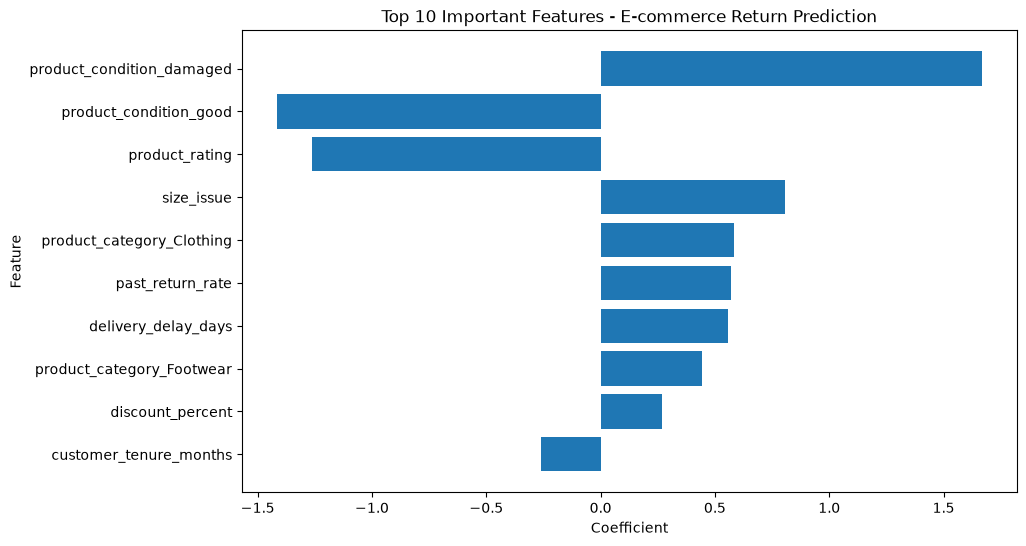

In [73]:
import matplotlib.pyplot as plt

top10 = coef_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top10["Feature"], top10["Coefficient"])
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Top 10 Important Features - E-commerce Return Prediction")
plt.gca().invert_yaxis()
plt.show()

In [74]:
df["order_value"] = df["product_price"] * df["quantity"]

total_order_value = df["order_value"].sum()

returned_value = df.loc[df["returned"] == 1, "order_value"].sum()

non_returned_value = df.loc[df["returned"] == 0, "order_value"].sum()

return_value_percentage = (returned_value / total_order_value) * 100

print("Total Order Value:", total_order_value)
print("Returned Order Value:", returned_value)
print("Non-Returned Order Value:", non_returned_value)
print("Return Value Impact (%):", return_value_percentage)

Total Order Value: 2186892.12
Returned Order Value: 1045044.78
Non-Returned Order Value: 1141847.34
Return Value Impact (%): 47.78675502292267


In [75]:
average_order_value = df["order_value"].mean()

return_rate = df["returned"].mean()

estimated_return_loss = average_order_value * return_rate

print("Average Order Value:", average_order_value)
print("Return Rate:", return_rate)
print("Estimated Return Loss per Order:", estimated_return_loss)

Average Order Value: 72.896404
Return Rate: 0.46503333333333335
Estimated Return Loss per Order: 33.899257740133336


In [76]:
import numpy as np
import pickle

np.save("weights.npy", weights)

with open("bias.pkl", "wb") as f:
    pickle.dump(bias, f)

with open("encoder.pkl", "wb") as f:
    pickle.dump(encoder, f)

with open("scaler.pkl", "wb") as f:
    pickle.dump(scaler, f)

print("Model files saved successfully.")

Model files saved successfully.
